# Unión de las bases geoespaciales por vía — Malla vial, puentes, malla peatonal, semáforos y siniestralidad

Este cuaderno une las capas geoespaciales base tomando la **vía original completa** (sin
subdividir en tramos) como unidad de análisis, y asigna cada elemento de infraestructura y de
siniestralidad a la vía más cercana mediante vecino más próximo (`sjoin_nearest`):

1. La **malla vial** recortada al perímetro POT se conserva con la longitud real de cada vía,
   sin subdividir en tramos de longitud fija.
2. Puentes, semáforos, malla peatonal y **siniestralidad peatonal** se asignan cada uno a la
   vía más cercana.
3. El resultado es una tabla a nivel de vía: una fila = una vía (o una parte de una vía
   multiparte), con sus atributos propios, su dotación de infraestructura y su **conteo de
   siniestros peatonales**, que es la variable objetivo de este cuaderno.

**Insumos requeridos** (generados por los cuadernos previos):

| Archivo | Origen |
|---|---|
| `Data/raw/perimetrourbano (1).gpkg` | POT Decreto 555 |
| `Data/processed/malla_vial_procesada.gpkg` | `EDA_Malla_Vial_Puentes_zona_urbana.ipynb` |
| `Data/processed/puentes_procesado.gpkg` | idem |
| `Data/processed/peatonal_procesada.gpkg` | `EDA_Malla_peatonal_semaforos.ipynb` |
| `Data/processed/semaforos_procesados.gpkg` | idem |
| `Data/processed/siniestros_procesados.gpkg` | `EDA2_Siniestros_Viales_Bogota_peatones...ipynb` (sección 9) |
| `anexo-proyecciones-poblacion-bogota-desagreacion-loc-2018-2035-UPZ-2018-2024.xlsx` | DANE / SDP — proyecciones de población por localidad, 2018-2035 |

Todo en **EPSG:3116** (MAGNA-SIRGAS / Bogotá), condición necesaria para que las distancias
estén en metros reales.


El cuaderno está organizado así:

1. Librerías y parámetros del diseño
2. Carga de insumos y estandarización de CRS
3. Vías como unidad de análisis (sin subdivisión)
4. Agregación de las capas a cada segmento (vecino más cercano)
5. Construcción del dataset final por segmento
6. Vista espacial del resultado
7. Exportación
8. Resumen metodológico

## 1. Librerías y parámetros del diseño

In [3]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 80)
plt.rcParams['figure.figsize'] = (9, 6)

# ---------------------------------------------------------------
# PARÁMETROS DEL DISEÑO METODOLÓGICO
# ---------------------------------------------------------------
CRS_PROYECTO = 3116          # MAGNA-SIRGAS / Colombia Bogotá zone (metros)
UMBRAL_RUIDO = 4             # descarta geometrías degeneradas de digitalización
UMBRAL_PEATONAL_M = 15       # distancia máxima para asignar un tramo peatonal a una vía
UMBRAL_SINIESTROS_M = 30     # distancia máxima para asignar un siniestro a una vía

DIR_PROC = 'Data/processed'
os.makedirs(DIR_PROC, exist_ok=True)

print(f"Umbral peatonal: {UMBRAL_PEATONAL_M} m | Umbral siniestros: {UMBRAL_SINIESTROS_M} m")

Umbral peatonal: 15 m | Umbral siniestros: 30 m


## 2. Carga de insumos y estandarización de CRS

Se fuerza el CRS de todas las capas a `EPSG:3116` en vez de asumirlo. Un CRS mal etiquetado
(grados tratados como metros) no falla de forma visible: produce distancias sin sentido físico.

In [4]:
def cargar(ruta, nombre):
    gdf = gpd.read_file(ruta)
    if gdf.crs is None:
        raise ValueError(f"{nombre}: la capa no tiene CRS definido; no se puede asumir.")
    if gdf.crs.to_epsg() != CRS_PROYECTO:
        gdf = gdf.to_crs(epsg=CRS_PROYECTO)
    n0 = len(gdf)
    gdf = gdf[~gdf.geometry.isna() & ~gdf.geometry.is_empty].copy()
    print(f"{nombre:11s}: {n0:>8,} -> {len(gdf):>8,} (descartadas {n0-len(gdf):,} sin geometría)")
    return gdf

perimetro  = cargar("Data/raw/perimetrourbano (1).gpkg", 'perimetro')
malla      = cargar(f"{DIR_PROC}/malla_vial_procesada.gpkg", 'malla')
puentes    = cargar(f"{DIR_PROC}/puentes_procesado.gpkg", 'puentes')
peatonal   = cargar(f"{DIR_PROC}/peatonal_procesada.gpkg", 'peatonal')
semaforos  = cargar(f"{DIR_PROC}/semaforos_procesados.gpkg", 'semaforos')
siniestros = cargar(f"{DIR_PROC}/siniestros_procesados.gpkg", 'siniestros')

# El perímetro se reduce a una sola geometría disuelta: es una máscara, no una tabla.
perimetro = gpd.GeoDataFrame(geometry=[perimetro.union_all()], crs=perimetro.crs)

for nombre, capa in [('perimetro', perimetro), ('malla', malla), ('puentes', puentes),
                     ('peatonal', peatonal), ('semaforos', semaforos), ('siniestros', siniestros)]:
    print(f"{nombre:11s} -> {len(capa):>8,} filas | {capa.crs.to_epsg()} | "
          f"{sorted(capa.geom_type.unique())}")

c:\Users\santiago\Desktop\Universidad\Tesis\Programacion\TT\.venv\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: Non-conformant content for record 1 in column FECHA_ACTO_ADMINISTRATIVO, 2022-07-29T00:00:00.0Z, successfully parsed
  return ogr_read(


perimetro  :        6 ->        6 (descartadas 0 sin geometría)
malla      :  136,957 ->  136,957 (descartadas 0 sin geometría)
puentes    :    1,212 ->    1,212 (descartadas 0 sin geometría)
peatonal   :   46,065 ->   46,065 (descartadas 0 sin geometría)
semaforos  :    1,745 ->    1,745 (descartadas 0 sin geometría)
siniestros :   23,447 ->   21,893 (descartadas 1,554 sin geometría)
perimetro   ->        1 filas | 3116 | ['MultiPolygon']
malla       ->  136,957 filas | 3116 | ['MultiLineString']
puentes     ->    1,212 filas | 3116 | ['MultiPolygon']
peatonal    ->   46,065 filas | 3116 | ['MultiLineString']
semaforos   ->    1,745 filas | 3116 | ['Point']
siniestros  ->   21,893 filas | 3116 | ['Point']


### 2.1 Recorte al perímetro urbano

Mismo criterio para todas las capas: lo que queda fuera del POT no entra al modelo. Se hace
antes de asignar las capas para no gastar cómputo con elementos que después se descartan.

Los semáforos se filtran aparte por coordenadas imposibles (registros corruptos de fuente,
no error de CRS) — ese diagnóstico ya venía del cuaderno anterior.

In [5]:
# Semáforos: exclusión de coordenadas físicamente imposibles (fuera de cualquier
# proyección válida para Bogotá). Se separa del clip porque es un problema de calidad
# de fuente, no de delimitación urbana.
minx, miny, maxx, maxy = perimetro.total_bounds
MARGEN = 5000
corruptos = semaforos[
    (semaforos.geometry.x < minx - MARGEN) | (semaforos.geometry.x > maxx + MARGEN) |
    (semaforos.geometry.y < miny - MARGEN) | (semaforos.geometry.y > maxy + MARGEN)
]
print(f"Semáforos con coordenada corrupta excluidos: {len(corruptos)} de {len(semaforos)}")
semaforos = semaforos.drop(index=corruptos.index).copy()

# Clip al POT de todas las capas
capas = {}
for nombre, capa in [('malla', malla), ('puentes', puentes), ('peatonal', peatonal),
                     ('semaforos', semaforos), ('siniestros', siniestros)]:
    antes = len(capa)
    recortada = gpd.clip(capa, perimetro)
    capas[nombre] = recortada
    print(f"{nombre:11s}: {antes:>8,} -> {len(recortada):>8,} "
          f"({len(recortada)/antes*100:5.1f}% conservado)")
    assert len(recortada) / antes > 0.80, \
        f"{nombre}: el recorte al POT conserva solo {len(recortada)/antes*100:.1f} % — revisar CRS del perímetro"

malla, puentes, peatonal, semaforos, siniestros = (
    capas['malla'], capas['puentes'], capas['peatonal'],
    capas['semaforos'], capas['siniestros'])

Semáforos con coordenada corrupta excluidos: 1 de 1745
malla      :  136,957 ->  131,874 ( 96.3% conservado)
puentes    :    1,212 ->    1,068 ( 88.1% conservado)
peatonal   :   46,065 ->   45,964 ( 99.8% conservado)
semaforos  :    1,744 ->    1,733 ( 99.4% conservado)
siniestros :   21,893 ->   21,716 ( 99.2% conservado)


## 3. Vías como unidad de análisis (sin subdivisión)

Cada vía original se conserva **completa**, con su longitud real, en vez de subdividirse en
tramos de longitud fija: evita introducir cortes artificiales y los tramos de borde que esos
cortes generaban. La longitud de cada vía queda disponible en `long_seg_m`, y es la que hay
que tener en cuenta al comparar conteos entre vías de tamaños muy distintos — una avenida larga
va a acumular más siniestros solo por tener más metros de exposición, no necesariamente porque
sea más peligrosa.

### 3.1 Identificador de la vía madre y filtro de ruido

Se conserva `vial_id` (código original MVI) para poder identificar cada vía, y se descartan
las geometrías por debajo del umbral de ruido: no tiene sentido tratar como vía algo que no
lo es.

In [6]:
id_col = 'MVICODIGO' if 'MVICODIGO' in malla.columns else 'OBJECTID'
malla_base = malla.rename(columns={id_col: 'vial_id'}).copy()

cols_utiles = [c for c in ['vial_id','MVINUMC', 'MVITIPO', 'MVISVIA', 'geometry', 'MVI_VELREG',] if c in malla_base.columns]
malla_base = malla_base[cols_utiles]

# Explotar multipartes y descartar ruido de digitalización
malla_base = malla_base.explode(index_parts=False).reset_index(drop=True)
malla_base['long_m'] = malla_base.geometry.length

antes = len(malla_base)
malla_base = malla_base[malla_base['long_m'] >= UMBRAL_RUIDO].copy()
print(f"Geometrías descartadas por ruido (< {UMBRAL_RUIDO} m): {antes - len(malla_base)}")
print(f"Vías conservadas: {len(malla_base):,}")
print(f"Longitud total de red: {malla_base['long_m'].sum():,.0f} m")

Geometrías descartadas por ruido (< 4 m): 305
Vías conservadas: 131,705
Longitud total de red: 8,150,422 m


In [7]:
def segmentar_capa(gdf):
    """Cada vía original (tras explotar multipartes) se conserva como un único
    segmento, con su longitud real — ya no se subdivide en tramos de longitud fija.
    Se mantiene el nombre por compatibilidad con el resto del pipeline."""
    base = gdf.explode(index_parts=False).reset_index(drop=True)
    base = base[base.geom_type == 'LineString'].copy()

    seg = base.copy()
    seg['linea_madre_idx'] = seg.index
    seg['long_seg_m'] = seg.geometry.length
    seg = seg.reset_index(drop=True)
    seg['seg_id'] = 'S' + seg.index.astype(str).str.zfill(7)
    return seg

segmentos = segmentar_capa(malla_base)

print(f"Vías (segmentos): {len(segmentos):,}")
print(segmentos['long_seg_m'].describe().round(2))
print(f"\nLongitud total de red: {segmentos['long_seg_m'].sum():,.0f} m")

Vías (segmentos): 131,705
count    131705.00
mean         61.88
std          49.96
min           4.01
25%          31.09
50%          49.59
75%          81.02
max        2893.62
Name: long_seg_m, dtype: float64

Longitud total de red: 8,150,422 m


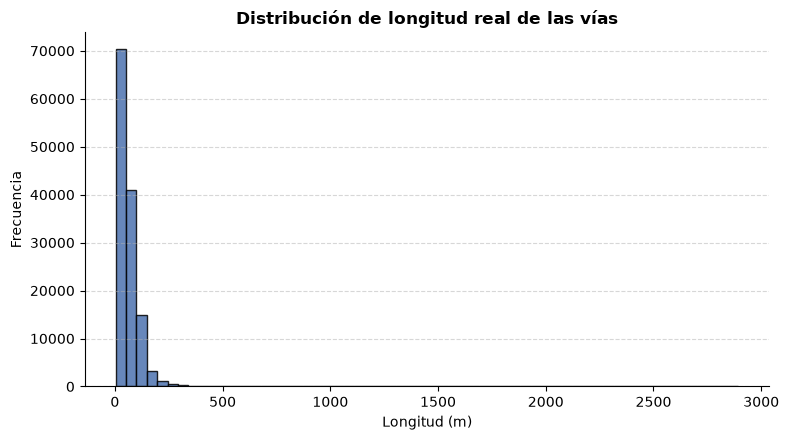

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(segmentos['long_seg_m'], bins=60, color='#4C72B0', edgecolor='black', alpha=0.85)
ax.set_title('Distribución de longitud real de las vías', fontweight='bold')
ax.set_xlabel('Longitud (m)'); ax.set_ylabel('Frecuencia')
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout(); plt.show()

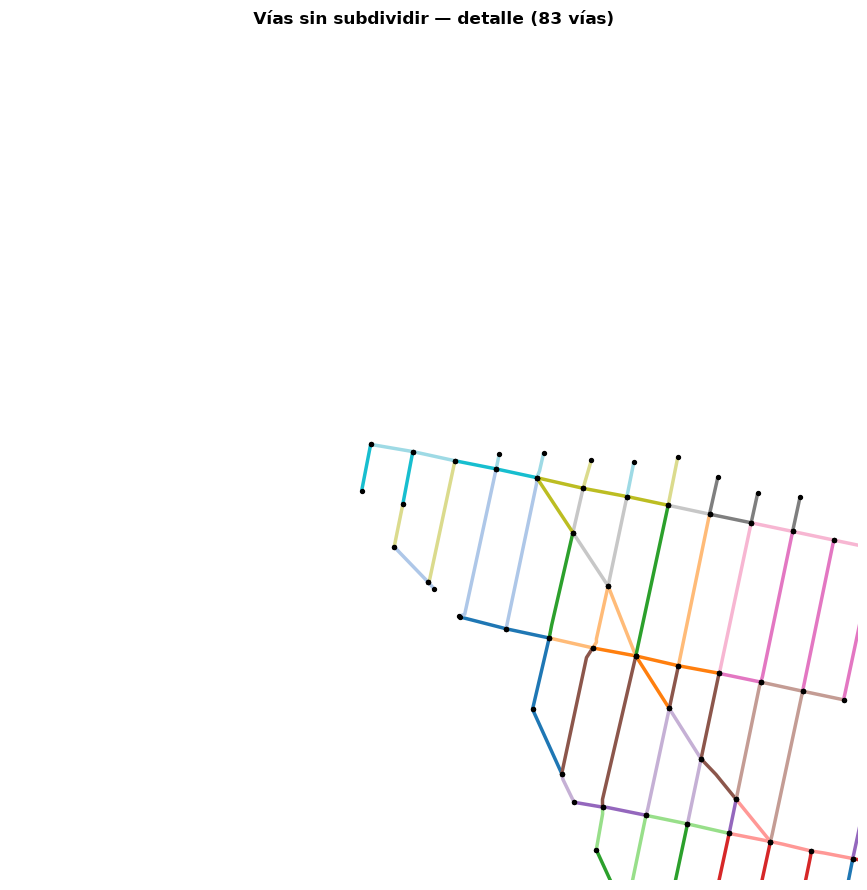

In [9]:
# Inspección visual en una ventana pequeña: cada vía en un color distinto
cx, cy = segmentos.geometry.iloc[len(segmentos)//2].centroid.coords[0]
R = 300

ventana = segmentos.cx[cx-R:cx+R, cy-R:cy+R]
fig, ax = plt.subplots(figsize=(9, 9))
ventana.plot(ax=ax, column='seg_id', cmap='tab20', linewidth=2.5, legend=False)
ventana.geometry.boundary.plot(ax=ax, color='black', markersize=8, zorder=3)
ax.set_xlim(cx-R, cx+R); ax.set_ylim(cy-R, cy+R)
ax.set_title(f'Vías sin subdividir — detalle ({len(ventana)} vías)', fontweight='bold')
ax.set_axis_off(); plt.tight_layout(); plt.show()

## 4. Agregación de las capas a cada segmento (vecino más cercano)

### 4.1 Nota metodológica: asignación por vecino más próximo

Cada elemento de las capas de
infraestructura y de siniestralidad se asigna a la vía más cercana mediante `sjoin_nearest`:

- **Puentes y semáforos** se resumen como **distancia al más cercano**, sin límite de
  distancia — la métrica en sí es la distancia, así que no hace falta descartar nada.
- **Malla peatonal y siniestros** se **agregan** (longitud sumada / conteo) a la vía más
  cercana dentro de un umbral de distancia (`UMBRAL_PEATONAL_M`, `UMBRAL_SINIESTROS_M`), para
  no asignarle a una vía infraestructura o siniestros que en realidad están lejos de ella.




### 4.2 Puentes

Los puentes son polígonos, pero aquí se resumen como la **distancia (m) de la vía al puente
más cercano**, mediante vecino más próximo, sin límite de distancia. Una distancia de 0
significa que la vía cruza o toca físicamente un puente.

In [10]:
# SUPUESTO A VERIFICAR con IDECA/IDU: 1 = Vehicular (catálogo IDECA), 2 = Peatonal (por confirmar)
TIPO_VEHICULAR = 1
TIPO_PEATONAL  = 2   # si la verificación indica otro código, cambiar SOLO aquí

COL_ID_PUENTE = 'PueCodigo' if 'PueCodigo' in puentes.columns else puentes.columns[0]

def _dist_min_a(capa, nombre_col):
    """Distancia (m) de cada segmento al elemento más cercano de `capa`, sin límite de distancia."""
    cercano = gpd.sjoin_nearest(
        segmentos[['seg_id', 'geometry']],
        capa[[COL_ID_PUENTE, 'geometry']],
        distance_col=nombre_col
    )
    # groupby.min resuelve los empates que sjoin_nearest devuelve como filas duplicadas
    return cercano.groupby('seg_id', as_index=False)[nombre_col].min()

def agregar_puentes():
    """Distancias (m) de cada vía al puente más cercano: peatonal, vehicular y de cualquier tipo."""
    puentes_peat = puentes[puentes['PueTipo'] == TIPO_PEATONAL]
    puentes_veh  = puentes[puentes['PueTipo'] == TIPO_VEHICULAR]

    res = _dist_min_a(puentes, 'dist_puente_m')
    if len(puentes_peat):
        res = res.merge(_dist_min_a(puentes_peat, 'dist_puente_peatonal_m'), on='seg_id', how='left')
    if len(puentes_veh):
        res = res.merge(_dist_min_a(puentes_veh, 'dist_puente_vehicular_m'), on='seg_id', how='left')
    return res

puentes_agg = agregar_puentes()

for col, etiqueta in [('dist_puente_m', 'cualquier puente'),
                      ('dist_puente_peatonal_m', 'puente peatonal (supuesto tipo 2)'),
                      ('dist_puente_vehicular_m', 'puente vehicular (tipo 1)')]:
    if col in puentes_agg:
        s = puentes_agg[col]
        print(f"Distancia a {etiqueta} -> media {s.mean():.1f} m | mediana {s.median():.1f} m | "
              f"vías sobre un puente (dist=0): {(s == 0).sum():,} | "
              f"vías con dato: {s.notna().sum():,} de {len(segmentos):,}")

Distancia a cualquier puente -> media 463.5 m | mediana 379.4 m | vías sobre un puente (dist=0): 3,261 | vías con dato: 131,705 de 131,705
Distancia a puente peatonal (supuesto tipo 2) -> media 573.5 m | mediana 481.8 m | vías sobre un puente (dist=0): 1,148 | vías con dato: 131,705 de 131,705
Distancia a puente vehicular (tipo 1) -> media 594.3 m | mediana 504.5 m | vías sobre un puente (dist=0): 2,361 | vías con dato: 131,705 de 131,705


### 4.3 Semáforos

Puntos: se resumen como la **distancia (m) al semáforo más cercano**, mediante vecino más
próximo, sin límite de distancia.

In [11]:
COL_ID_SEM = 'OBJECTID' if 'OBJECTID' in semaforos.columns else semaforos.columns[0]

def agregar_semaforos():
    """Distancia (m) de cada vía al semáforo más cercano, sin límite de distancia."""
    cercano = gpd.sjoin_nearest(
        segmentos[['seg_id', 'geometry']],
        semaforos[[COL_ID_SEM, 'geometry']],
        distance_col='dist_semaforo_m'
    )
    return (cercano.groupby('seg_id', as_index=False)['dist_semaforo_m'].min())

semaforos_agg = agregar_semaforos()
print(f"Distancia al semáforo más cercano -> media {semaforos_agg['dist_semaforo_m'].mean():.1f} m | "
      f"mediana {semaforos_agg['dist_semaforo_m'].median():.1f} m | "
      f"máxima {semaforos_agg['dist_semaforo_m'].max():.1f} m | "
      f"vías con dato: {semaforos_agg['dist_semaforo_m'].notna().sum():,} de {len(segmentos):,}")

Distancia al semáforo más cercano -> media 401.7 m | mediana 238.8 m | máxima 4976.2 m | vías con dato: 131,705 de 131,705


### 4.4 Malla peatonal

Es una capa de **líneas**, así que un conteo de elementos dice poco (depende de cómo esté
fragmentada la fuente). Cada tramo de malla peatonal se asigna a la vía más cercana (hasta
`UMBRAL_PEATONAL_M`) mediante vecino más próximo, y se suma la longitud de los tramos
asignados: la variable informativa es la **longitud de infraestructura peatonal asignada a la
vía**, y su versión normalizada por longitud de vía (metros de andén por metro de vía), que es
comparable entre vías de distinta longitud.

In [12]:
def agregar_peatonal(umbral_m=UMBRAL_PEATONAL_M):
    """Para cada vía, tramo peatonal más cercano (invertido respecto a antes: se
    consulta desde la vía, no desde el tramo peatonal, para que vías vecinas no
    compitan por un mismo tramo peatonal)."""
    peatonal_ = peatonal.copy()
    peatonal_['long_peat_elem'] = peatonal_.geometry.length

    cercano = gpd.sjoin_nearest(
        segmentos[['seg_id', 'geometry']],
        peatonal_[['long_peat_elem', 'geometry']],
        max_distance=umbral_m, distance_col='dist_peatonal_m'
    )
    # Si una vía tiene dos tramos peatonales exactamente a la misma distancia mínima,
    # sjoin_nearest puede duplicar la fila; nos quedamos con uno solo por vía.
    cercano = cercano.drop_duplicates(subset='seg_id', keep='first')

    return cercano[['seg_id', 'dist_peatonal_m', 'long_peat_elem']].rename(
        columns={'long_peat_elem': 'long_peatonal_cercano_m'})

peatonal_agg = agregar_peatonal()
print(f"Vías con infraestructura peatonal asignada (<= {UMBRAL_PEATONAL_M} m): "
      f"{len(peatonal_agg):,} ({len(peatonal_agg)/len(segmentos)*100:.2f}%) | "
      f"distancia media: {peatonal_agg['dist_peatonal_m'].mean():.2f} m")

Vías con infraestructura peatonal asignada (<= 15 m): 74,417 (56.50%) | distancia media: 0.23 m


### 4.5 Conteo de siniestros por segmento (variable objetivo)

El **conteo de siniestros peatonales por vía** es la variable objetivo de este cuaderno. Cada
siniestro se asigna a la vía más cercana (hasta `UMBRAL_SINIESTROS_M`) mediante vecino más
próximo, así que cada siniestro pertenece a una única vía — no hay doble conteo que resolver.
Se agrega con más detalle que las covariables: conteo total de siniestros, número de peatones
afectados, y descriptores de contexto adicionales (desagregación por `ESTADO`, porcentaje
nocturno y momento del siniestro) que quedan disponibles como variables descriptivas, no como
la definición del objetivo.

In [13]:
print("Columnas disponibles en siniestros:")
print(sorted(siniestros.columns.tolist()))
print()
if 'ESTADO' in siniestros.columns:
    print(siniestros['ESTADO'].value_counts(dropna=False))

Columnas disponibles en siniestros:
['ANO_OCURRENCIA_ACC', 'CAUSA_PRINCIPAL', 'CLASE', 'CODIGO_ACCIDENTADO', 'CODIGO_ACCIDENTE', 'CODIGO_LOCALIDAD', 'CONDICION', 'DIA_SEMANA', 'DIRECCION', 'DISENO_LUGAR', 'DISENO_LUGAR_DESC', 'EDAD', 'ESTADO', 'FECHA', 'FECHA_HORA_ACC', 'FECHA_OCURRENCIA_ACC', 'HORA', 'HORA_DIA', 'LATITUD', 'LOCALIDAD_DESC', 'LONGITUD', 'MES', 'SEXO', 'VEHICULO', 'geometry']

ESTADO
HERIDO    20327
MUERTO     1387
ILESO         2
Name: count, dtype: int64


In [14]:
siniestros.head()

,CODIGO_ACCIDENTE,CODIGO_ACCIDENTADO,FECHA,CONDICION,ESTADO,EDAD,SEXO,VEHICULO,CAUSA_PRINCIPAL,CODIGO_LOCALIDAD,DISENO_LUGAR,DIRECCION,HORA,CLASE,LATITUD,LONGITUD,DISENO_LUGAR_DESC,FECHA_OCURRENCIA_ACC,ANO_OCURRENCIA_ACC,FECHA_HORA_ACC,MES,DIA_SEMANA,HORA_DIA,LOCALIDAD_DESC,geometry
14577,10448127,12553026,18/05/2018,PEATON,HERIDO,62.0,MASCULINO,None,Otras (peatón),7,1,AV AVENIDA DEL SUR-KR 70C 02,17:16:00,2,4.598553,-74.193499,Tramo de Via,2018-05-18 00:00:00+00:00,2018.0,2018-05-18 17:16:00+00:00,5.0,Friday,17.0,Bosa,POINT (987129.191 1000261.143)
330,4403841,2457699,03/02/2015,PEATON,HERIDO,53.0,MASCULINO,None,Otras (peatón),7,1,AV AVENIDA DEL SUR-CL 71 75,05:20:00,2,4.598933,-74.194200,Tramo de Via,2015-02-03 00:00:00+00:00,2015.0,2015-02-03 05:20:00+00:00,2.0,Tuesday,5.0,Bosa,POINT (987051.486 1000303.228)
18103,10478726,12618644,15/03/2019,PEATON,HERIDO,6.0,MASCULINO,None,Otra (conductor en general),7,1,CL 71A-KR 77ABIS S 42,20:50:00,2,4.598955,-74.194502,Tramo de Via,2019-03-15 00:00:00+00:00,2019.0,2019-03-15 20:50:00+00:00,3.0,Friday,20.0,Bosa,POINT (987017.953 1000305.629)
14316,4516188,2698788,27/04/2018,PEATON,HERIDO,22.0,FEMENINO,None,Otra (conductor en general),19,2,DG 71B-TR 85 2,20:50:00,3,4.598973,-74.194498,Interseccion,2018-04-27 00:00:00+00:00,2018.0,2018-04-27 20:50:00+00:00,4.0,Friday,20.0,Ciudad Bolívar,POINT (987018.358 1000307.704)
18683,10483837,12629565,06/05/2019,PEATON,HERIDO,16.0,MASCULINO,None,Cruzar sin observar (peatón),7,2,CL 71A-KR 77C S 2,12:00:00,2,4.599024,-74.194509,Interseccion,2019-05-06 00:00:00+00:00,2019.0,2019-05-06 12:00:00+00:00,5.0,Monday,12.0,Bosa,POINT (987017.159 1000313.25)


In [15]:
def agregar_siniestros(umbral_m=UMBRAL_SINIESTROS_M):
    base_sin = siniestros.reset_index(drop=True).copy()
    base_sin['_elem_id'] = base_sin.index

    pares = gpd.sjoin_nearest(
        base_sin, segmentos[['seg_id', 'geometry']],
        max_distance=umbral_m, distance_col='dist_m'
    )
    # Empates a la misma distancia mínima: nos quedamos con uno solo por siniestro
    pares = pares.drop_duplicates(subset='_elem_id', keep='first')

    sin_asignar = len(base_sin) - pares['_elem_id'].nunique()
    print(f"Siniestros sin vía asignada a {umbral_m} m: {sin_asignar}")

    col_acc = 'CODIGO_ACCIDENTE' if 'CODIGO_ACCIDENTE' in pares.columns else '_elem_id'

    agg = {'n_peatones_afectados': ('_elem_id', 'nunique'),
           'n_siniestros': (col_acc, 'nunique')}
    if 'HORA_DIA' in pares.columns:
        agg['pct_nocturno'] = ('HORA_DIA', lambda s: ((s >= 19) | (s <= 5)).mean() * 100)
    # La población ya no se agrega aquí: se asigna a cada vía directamente por su localidad
    # (sección 4.7), sin pasar por los siniestros que caigan cerca.

    base = pares.groupby('seg_id').agg(**agg).reset_index()

    # Desagregación por gravedad: una columna por estado del peatón (se excluye 'ileso',
    # no aporta como variable de este dataset)
    if 'ESTADO' in pares.columns:
        piv = (pd.crosstab(pares['seg_id'], pares['ESTADO'])
                 .add_prefix('n_').rename(columns=str.lower).reset_index())
        if 'n_ileso' in piv.columns:
            piv = piv.drop(columns='n_ileso')
        base = base.merge(piv, on='seg_id', how='left')

    # Año más reciente y rango temporal cubierto en la vía
    if 'ANO_OCURRENCIA_ACC' in pares.columns:
        años = (pares.groupby('seg_id')['ANO_OCURRENCIA_ACC']
                     .agg(ano_min='min', ano_max='max').reset_index())
        base = base.merge(años, on='seg_id', how='left')

    return base

siniestros_agg = agregar_siniestros()

print(f"\nVías con siniestro: {len(siniestros_agg):,} ({len(siniestros_agg)/len(segmentos)*100:.2f}%) | "
      f"total asignaciones: {siniestros_agg['n_peatones_afectados'].sum():,} "
      f"(peatones afectados reales: {len(siniestros):,})")

Siniestros sin vía asignada a 30 m: 15

Vías con siniestro: 13,323 (10.12%) | total asignaciones: 21,701 (peatones afectados reales: 21,716)


### 4.6 Cobertura: ¿qué siniestros no captura el umbral de distancia?

Un siniestro que no cae dentro de `UMBRAL_SINIESTROS_M` de ninguna vía queda **fuera del
modelo**: o su geocodificación es imprecisa, o ocurrió en una vía que no está en la Malla Vial
Integral. Si esta fracción es alta, es el argumento empírico para subir el umbral.

In [16]:
pct_cobertura = siniestros_agg['n_peatones_afectados'].sum() / len(siniestros) * 100
print(f"Cobertura con umbral de {UMBRAL_SINIESTROS_M} m: {pct_cobertura:.2f}% de los "
      f"siniestros peatonales quedaron asignados a alguna vía.")

Cobertura con umbral de 30 m: 99.93% de los siniestros peatonales quedaron asignados a alguna vía.


### 4.7 Integración de la población por localidad

**Cambio respecto a la versión anterior.** Antes, la población llegaba a cada vía de forma
indirecta: se unía al siniestro (por localidad y año del siniestro) y luego se propagaba a la
vía como el promedio de la población de los siniestros asignados a ella
(`poblacion_localidad_media` dentro de `agregar_siniestros`). Esto dejaba sin población a toda
vía sin un siniestro a ≤ 30 m, es decir, a la gran mayoría de la red (~90 %), aunque esas vías
evidentemente sí pertenecen a alguna localidad.

Ahora la población se asigna **directamente a la vía**, por su posición espacial dentro de una
localidad, sin pasar por los siniestros. Esto requiere una capa de polígonos de localidades que
la malla vial no trae de forma nativa (`vial_id`, `MVITIPO`, `MVISVIA` no identifican localidad).

**[PENDIENTE: agregar la capa de localidades a `Data/raw/`]** — por ejemplo, la capa oficial de
localidades de Bogotá (IDECA / Datos Abiertos). Ajusta `RUTA_LOCALIDADES` y, si hace falta, la
lista `CANDIDATOS_LOCALIDAD_POLY` con el nombre real de la columna que trae el nombre de la
localidad en esa capa.

In [17]:
RUTA_ANEXO_POBLACION = "Data/raw/anexo-proyecciones-poblacion-bogota-desagreacion-loc-2018-2035-UPZ-2018-2024.xlsx"

# La hoja trae 11 filas de título/metadatos antes del encabezado real de columnas
poblacion_raw = pd.read_excel(RUTA_ANEXO_POBLACION, sheet_name='Localidades', header=11)
poblacion_raw = poblacion_raw[poblacion_raw['NOM_LOC'].notna() & (poblacion_raw['NOM_LOC'] != 'NOM_LOC')].copy()

poblacion_localidad = (
    poblacion_raw[poblacion_raw['AREA'] == 'Total']
    [['COD_LOC', 'NOM_LOC', 'AÑO', 'TOTAL HOMBRES', 'TOTAL MUJERES', 'TOTAL']]
    .rename(columns={'AÑO': 'anio', 'TOTAL': 'poblacion_total',
                      'TOTAL HOMBRES': 'poblacion_hombres', 'TOTAL MUJERES': 'poblacion_mujeres'})
    .reset_index(drop=True)
)
poblacion_localidad['anio'] = poblacion_localidad['anio'].astype(int)

print(f"Anexo cargado: {len(poblacion_localidad):,} filas | "
      f"{poblacion_localidad['NOM_LOC'].nunique()} localidades | "
      f"años {poblacion_localidad['anio'].min()}–{poblacion_localidad['anio'].max()}")
poblacion_localidad.head()

Anexo cargado: 360 filas | 20 localidades | años 2018–2035


,COD_LOC,NOM_LOC,anio,poblacion_hombres,poblacion_mujeres,poblacion_total
0,1,Usaquén,2018,246937,288756,535693
1,2,Chapinero,2018,74402,82077,156479
2,3,Santa Fe,2018,51631,52354,103985
3,4,San Cristóbal,2018,186898,198616,385514
4,5,Usme,2018,176971,186423,363394


**Normalización de nombres de localidad.** Los nombres de localidad en el anexo (con tildes,
capitalización estándar) no siempre coinciden carácter a carácter con los de la capa de
localidades ni con los de la fuente de siniestros. Se normaliza a mayúsculas sin tildes para que
el cruce por nombre sea robusto a esas diferencias de formato, en vez de exigir coincidencia
exacta.

In [18]:
import unicodedata

def normalizar_texto(s):
    """Mayúsculas, sin tildes, sin espacios sobrantes — para cruces de texto robustos."""
    if pd.isna(s):
        return s
    s = str(s).strip().upper()
    s = ''.join(c for c in unicodedata.normalize('NFD', s) if unicodedata.category(c) != 'Mn')
    return s

poblacion_localidad['loc_norm'] = poblacion_localidad['NOM_LOC'].map(normalizar_texto)

#### 4.7.1 Capa de localidades y asignación espacial a cada vía

Se asigna cada vía a la localidad que contiene su **centroide**, no su geometría completa: una
vía es una línea y puede atravesar el borde entre dos localidades, así que el centroide evita
asignaciones ambiguas o duplicadas. Para el puñado de vías cuyo centroide cae justo sobre un
borde o fuera de todos los polígonos por precisión numérica, se usa vecino más próximo como
respaldo, en vez de dejarlas sin localidad.

In [19]:
RUTA_LOCALIDADES = "Data/raw/localidades_bogota.gpkg"  # AJUSTAR si el archivo tiene otro nombre/ruta
CANDIDATOS_LOCALIDAD_POLY = ['LocNombre', 'LOCALIDAD', 'Nombre', 'NOMBRE', 'NOM_LOC', 'locnombre']

localidades = cargar(RUTA_LOCALIDADES, 'localidades')

col_loc_poly = next((c for c in CANDIDATOS_LOCALIDAD_POLY if c in localidades.columns), None)
if col_loc_poly is None:
    raise ValueError(
        "No se detectó automáticamente la columna de nombre de localidad en la capa de polígonos. "
        f"Columnas disponibles: {sorted(localidades.columns.tolist())}. "
        "Agrega el nombre correcto a CANDIDATOS_LOCALIDAD_POLY y vuelve a correr esta celda."
    )
print(f"Columna de nombre de localidad detectada: '{col_loc_poly}'")

localidades = localidades[[col_loc_poly, 'geometry']].rename(columns={col_loc_poly: 'localidad'})
localidades['loc_norm'] = localidades['localidad'].map(normalizar_texto)

localidades:       20 ->       20 (descartadas 0 sin geometría)
Columna de nombre de localidad detectada: 'LocNombre'


In [20]:
# Centroide de cada vía: una línea puede cruzar el borde entre dos localidades,
# el centroide evita que quede asignada a ambas o a ninguna.
centroides = segmentos[['seg_id', 'geometry']].copy()
centroides['geometry'] = centroides.geometry.centroid

vial_localidad = gpd.sjoin(
    centroides, localidades[['loc_norm', 'geometry']],
    how='left', predicate='within'
).drop(columns='index_right')[['seg_id', 'loc_norm']]
vial_localidad = vial_localidad.drop_duplicates(subset='seg_id', keep='first')

# Respaldo por vecino más próximo para centroides sobre un borde o fuera por precisión numérica
sin_loc = vial_localidad.loc[vial_localidad['loc_norm'].isna(), 'seg_id']
if len(sin_loc):
    faltantes = centroides[centroides['seg_id'].isin(sin_loc)]
    cercano = gpd.sjoin_nearest(
        faltantes, localidades[['loc_norm', 'geometry']]
    ).drop(columns='index_right')[['seg_id', 'loc_norm']]
    cercano = cercano.drop_duplicates(subset='seg_id', keep='first')
    vial_localidad = pd.concat([
        vial_localidad[~vial_localidad['seg_id'].isin(sin_loc)], cercano
    ], ignore_index=True)
    print(f"Vías asignadas por vecino más próximo (borde de localidad): {len(cercano):,}")

pct_con_localidad = vial_localidad['loc_norm'].notna().mean() * 100
print(f"Vías con localidad asignada: {pct_con_localidad:.2f}% "
      f"({vial_localidad['loc_norm'].notna().sum():,} de {len(segmentos):,})")

Vías con localidad asignada: 100.00% (131,705 de 131,705)


#### 4.7.2 Población representativa por localidad

La vía no tiene año: es una geometría fija, no un evento fechado, así que no puede heredar una
población distinta por año como sí hace cada siniestro individual. Se necesita entonces un único
valor de población por localidad que represente el periodo de estudio (2015–2020). Como el anexo
del DANE/SDP solo está disponible desde 2018, se usa el **promedio 2018–2020**, el tramo del
anexo que sí se solapa con el periodo de estudio.

**[PENDIENTE: confirmar si este promedio es el criterio deseado, o si conviene usar un año fijo
(p. ej. 2018, el primero disponible) u otra forma de representar la población del periodo
2015–2020 con datos que solo cubren 2018–2020.]**

In [21]:
ANIO_REPRESENTATIVO_INICIO = 2018
ANIO_REPRESENTATIVO_FIN = 2020

poblacion_repr = (
    poblacion_localidad[poblacion_localidad['anio'].between(ANIO_REPRESENTATIVO_INICIO, ANIO_REPRESENTATIVO_FIN)]
    .groupby('loc_norm', as_index=False)['poblacion_total'].mean()
    .rename(columns={'poblacion_total': 'poblacion_localidad'})
)
print(f"Población representativa calculada para {len(poblacion_repr)} localidades "
      f"(promedio {ANIO_REPRESENTATIVO_INICIO}-{ANIO_REPRESENTATIVO_FIN}).")
poblacion_repr

Población representativa calculada para 20 localidades (promedio 2018-2020).


,loc_norm,poblacion_localidad
0,ANTONIO NARINO,8.026533e+04
1,BARRIOS UNIDOS,1.382357e+05
2,BOSA,7.064213e+05
3,CHAPINERO,1.631377e+05
4,CIUDAD BOLIVAR,6.277010e+05
5,ENGATIVA,8.022567e+05
6,FONTIBON,3.766220e+05
7,KENNEDY,1.027167e+06
8,LA CANDELARIA,1.734367e+04
9,LOS MARTIRES,7.994133e+04


#### 4.7.3 Propagación a cada vía

Se une la localidad de cada vía (4.7.1) con su población representativa (4.7.2). El resultado,
`poblacion_segmento`, cubre la totalidad de la red —tenga o no siniestros— porque ya no depende
de que algún siniestro haya caído cerca.

In [22]:
poblacion_segmento = vial_localidad.merge(poblacion_repr, on='loc_norm', how='left').rename(
    columns={'loc_norm': 'localidad'}
)[['seg_id', 'localidad', 'poblacion_localidad']]

pct_con_poblacion = poblacion_segmento['poblacion_localidad'].notna().mean() * 100
print(f"Vías con población de localidad asignada: {pct_con_poblacion:.2f}% "
      f"({poblacion_segmento['poblacion_localidad'].notna().sum():,} de {len(segmentos):,})")

sin_match = sorted(
    poblacion_segmento.loc[poblacion_segmento['poblacion_localidad'].isna(), 'localidad'].dropna().unique()
)
if sin_match:
    print("Localidades sin coincidencia en el anexo de población (revisar ortografía):", sin_match)

Vías con población de localidad asignada: 99.55% (131,110 de 131,705)
Localidades sin coincidencia en el anexo de población (revisar ortografía): ['CANDELARIA']


#### 4.7.4 Tasa de siniestralidad por 100.000 habitantes, por localidad y año

Esta tabla es un indicador **descriptivo**, independiente del dataset por vía: responde "¿dónde
es más riesgoso caminar, ya corregido por tamaño poblacional?" a nivel de localidad y año. Para
esto sí tiene sentido cruzar cada siniestro con la población de su localidad **en el año en que
ocurrió**, porque aquí cada fila es un siniestro con fecha, no una vía estática.

In [23]:
CANDIDATOS_LOCALIDAD = ['LOCALIDAD', 'LOCALIDAD_ACC', 'LOCALIDAD_HECHO', 'LOCALIDAD_SIN',
                        'NOMBRE_LOCALIDAD', 'NOM_LOCALIDAD', 'LOC_NOMBRE', 'LOCALIDAD_DESC']
COL_LOCALIDAD_SIN = next((c for c in CANDIDATOS_LOCALIDAD if c in siniestros.columns), None)
COL_ANIO_SIN = 'ANO_OCURRENCIA_ACC' if 'ANO_OCURRENCIA_ACC' in siniestros.columns else None

if COL_LOCALIDAD_SIN and COL_ANIO_SIN:
    siniestros['_loc_norm'] = siniestros[COL_LOCALIDAD_SIN].map(normalizar_texto)
    siniestros['_anio_sin'] = pd.to_numeric(siniestros[COL_ANIO_SIN], errors='coerce').astype('Int64')

    anio_min, anio_max = poblacion_localidad['anio'].min(), poblacion_localidad['anio'].max()
    fuera_de_rango = ((siniestros['_anio_sin'] < anio_min) | (siniestros['_anio_sin'] > anio_max)).sum()
    if fuera_de_rango:
        print(f"{fuera_de_rango} siniestros con año fuera de {anio_min}-{anio_max}; "
              f"se emparejan con el límite más cercano del anexo.")
    siniestros['_anio_match'] = siniestros['_anio_sin'].clip(lower=anio_min, upper=anio_max)

    siniestros = siniestros.merge(
        poblacion_localidad[['loc_norm', 'anio', 'poblacion_total']],
        left_on=['_loc_norm', '_anio_match'], right_on=['loc_norm', 'anio'], how='left'
    ).drop(columns=['loc_norm', 'anio'])

    resumen_localidad_anio = (
        siniestros.dropna(subset=['poblacion_total'])
                  .groupby(['_loc_norm', '_anio_match'])
                  .agg(n_siniestros=('_anio_sin', 'size'),
                       poblacion_total=('poblacion_total', 'first'))
                  .reset_index()
                  .rename(columns={'_loc_norm': 'localidad', '_anio_match': 'anio'})
    )
    resumen_localidad_anio['siniestros_por_100k_hab'] = (
        resumen_localidad_anio['n_siniestros'] / resumen_localidad_anio['poblacion_total'] * 100_000
    ).round(2)
    resumen_localidad_anio = resumen_localidad_anio.sort_values(['localidad', 'anio']).reset_index(drop=True)
    print(resumen_localidad_anio.shape)
else:
    print("No se detectó columna de localidad y/o año en siniestros; se omite la tabla de tasas.")
    resumen_localidad_anio = pd.DataFrame()

resumen_localidad_anio.head(15)

11929 siniestros con año fuera de 2018-2035; se emparejan con el límite más cercano del anexo.
(57, 5)


,localidad,anio,n_siniestros,poblacion_total,siniestros_por_100k_hab
0,ANTONIO NARINO,2018,343,79229,432.92
1,ANTONIO NARINO,2019,82,80095,102.38
2,ANTONIO NARINO,2020,61,81472,74.87
3,BARRIOS UNIDOS,2018,485,133126,364.32
4,BARRIOS UNIDOS,2019,112,138316,80.97
5,BARRIOS UNIDOS,2020,52,143265,36.3
6,BOSA,2018,1035,694397,149.05
7,BOSA,2019,254,707173,35.92
8,BOSA,2020,142,717694,19.79
9,CHAPINERO,2018,657,156479,419.86


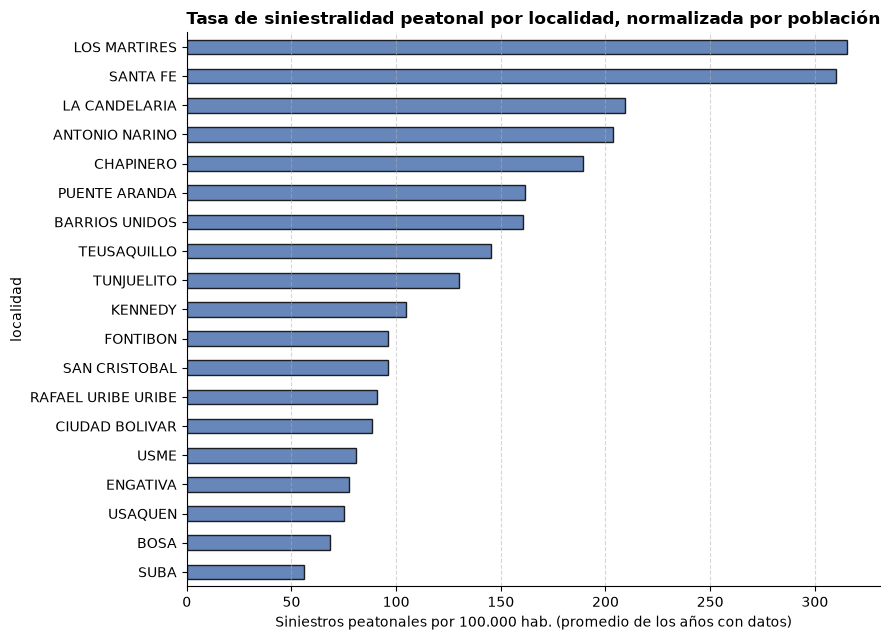

In [24]:
if len(resumen_localidad_anio):
    tasa_media_localidad = (resumen_localidad_anio.groupby('localidad')['siniestros_por_100k_hab']
                            .mean().sort_values(ascending=False))

    fig, ax = plt.subplots(figsize=(9, 6.5))
    tasa_media_localidad.plot(kind='barh', ax=ax, color='#4C72B0', edgecolor='black', alpha=0.85)
    ax.invert_yaxis()
    ax.set_xlabel('Siniestros peatonales por 100.000 hab. (promedio de los años con datos)')
    ax.set_title('Tasa de siniestralidad peatonal por localidad, normalizada por población',
                 fontweight='bold')
    ax.grid(axis='x', linestyle='--', alpha=0.5)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    plt.tight_layout(); plt.show()

## 5. Construcción del dataset final por segmento

Una fila = una vía. Las covariables de infraestructura y la variable respuesta —el **conteo
de siniestros por segmento**— vienen todas de una asignación por vecino más próximo, así que
no hace falta distinguir modos de agregación.

In [25]:
def construir_dataset():
    ds = segmentos[['seg_id', 'vial_id', 'long_seg_m', 'geometry'] +
                   [c for c in ['MVITIPO', 'MVISVIA','MVI_VELREG','MVINUMC'] if c in segmentos.columns]].copy()

    ds = ds.merge(puentes_agg,        on='seg_id', how='left')
    ds = ds.merge(semaforos_agg,      on='seg_id', how='left')
    ds = ds.merge(peatonal_agg,       on='seg_id', how='left')
    ds = ds.merge(siniestros_agg,     on='seg_id', how='left')
    # Población por localidad asignada directamente a la vía (sección 4.7): cubre el 100%
    # de la red, tenga o no siniestros, a diferencia del enfoque anterior vía siniestros.
    ds = ds.merge(poblacion_segmento, on='seg_id', how='left')

    # Conteos ausentes = ausencia real del fenómeno, no dato faltante
    cols_conteo = [c for c in ds.columns if c.startswith('n_')]
    ds[cols_conteo] = ds[cols_conteo].fillna(0)
    for c in cols_conteo:
        if ds[c].dropna().mod(1).eq(0).all():
            ds[c] = ds[c].astype(int)

    # Infraestructura peatonal: NaN en dist_peatonal_m = ninguna a <= UMBRAL_PEATONAL_M
    ds['tiene_infra_peatonal'] = ds['dist_peatonal_m'].notna()

    if 'n_peatones_afectados' in ds.columns:
        ds['tuvo_siniestro'] = ds['n_peatones_afectados'] > 0
    return ds

dataset_final = construir_dataset()

print(f"Dataset final: {dataset_final.shape}")
print(f"% con infraestructura peatonal asignada : {dataset_final['tiene_infra_peatonal'].mean()*100:.2f}%")
print(f"% con siniestro                         : {dataset_final['tuvo_siniestro'].mean()*100:.2f}%")
print(f"Siniestros totales capturados            : {dataset_final['n_peatones_afectados'].sum():,}")
print(f"% con población de localidad asignada    : {dataset_final['poblacion_localidad'].notna().mean()*100:.2f}%")
dataset_final.head()

Dataset final: (131705, 25)
% con infraestructura peatonal asignada : 56.50%
% con siniestro                         : 10.12%
Siniestros totales capturados            : 21,701
% con población de localidad asignada    : 99.55%


,seg_id,vial_id,long_seg_m,geometry,MVITIPO,MVISVIA,MVI_VELREG,MVINUMC,dist_puente_m,dist_puente_peatonal_m,dist_puente_vehicular_m,dist_semaforo_m,dist_peatonal_m,long_peatonal_cercano_m,n_peatones_afectados,n_siniestros,pct_nocturno,n_herido,n_muerto,ano_min,ano_max,localidad,poblacion_localidad,tiene_infra_peatonal,tuvo_siniestro
0,S0000000,91428,30.958381,"LINESTRING (988757.414 997892.228, 988727.382 ...",CL,SD,30.0,2.0,2149.708556,2149.708556,2248.410504,1410.063301,NaN,NaN,0,0,NaN,0,0,NaN,NaN,CIUDAD BOLIVAR,627701.0,False,False
1,S0000001,103844,35.729601,"LINESTRING (988786.272 997913.035, 988771.253 ...",CL,SD,30.0,2.0,2130.397897,2130.397897,2218.697332,1378.963885,NaN,NaN,0,0,NaN,0,0,NaN,NaN,CIUDAD BOLIVAR,627701.0,False,False
2,S0000002,136273,31.900881,"LINESTRING (988935.627 997898.403, 988910.141 ...",DG,SD,30.0,1.0,2108.777826,2108.777826,2173.881717,1232.553221,NaN,NaN,0,0,NaN,0,0,NaN,NaN,CIUDAD BOLIVAR,627701.0,False,False
3,S0000003,122955,48.556662,"LINESTRING (988745.967 997939.416, 988752.964 ...",KR,SD,30.0,1.0,2102.083822,2102.083822,2208.676848,1410.063301,NaN,NaN,0,0,NaN,0,0,NaN,NaN,CIUDAD BOLIVAR,627701.0,False,False
4,S0000004,106448,21.075999,"LINESTRING (988910.141 997917.589, 988899.533 ...",DG,SD,30.0,1.0,2106.174016,2106.174016,2164.688445,1255.390362,NaN,NaN,0,0,NaN,0,0,NaN,NaN,CIUDAD BOLIVAR,627701.0,False,False


In [26]:
dataset_final['MVI_VELREG'].unique()

array([30., 54., 36., 60., 48., 42.])

### 5.1 Desbalance de la variable respuesta (conteo de siniestros por segmento)

La mayoría de las vías de Bogotá no tuvo ningún siniestro peatonal. Cuantificarlo aquí
justifica las decisiones de modelado (pesos de clase, métricas distintas de exactitud) y
anticipa si conviene un modelo de conteos inflado en ceros.

Vías sin siniestros : 118,382 (89.88%)
Vías con >=1         : 13,323 (10.12%)
Máximo en una vía    : 54

Distribución de conteos:
n_peatones_afectados
0     118382
1       9116
2       2360
3        937
4        402
5        212
6        114
7         69
8         29
9         21
10        19
11        12
Name: count, dtype: int64


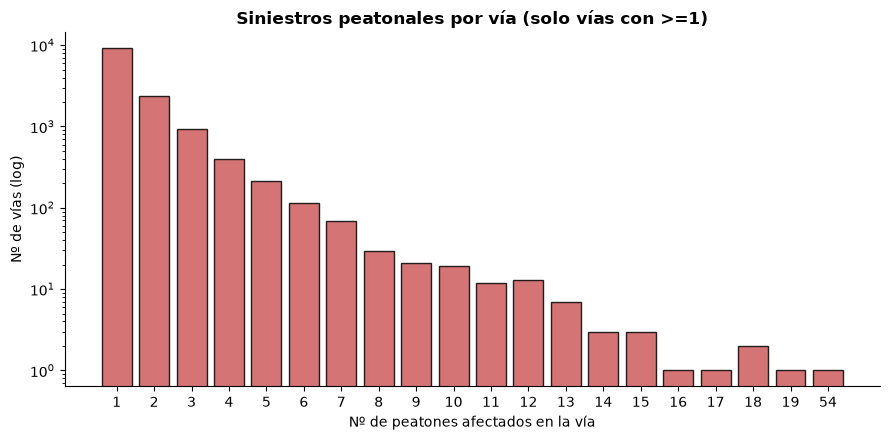

In [27]:
vr = dataset_final['n_peatones_afectados']
print(f"Vías sin siniestros : {(vr == 0).sum():,} ({(vr == 0).mean()*100:.2f}%)")
print(f"Vías con >=1         : {(vr > 0).sum():,} ({(vr > 0).mean()*100:.2f}%)")
print(f"Máximo en una vía    : {vr.max()}")
print(f"\nDistribución de conteos:")
print(vr.value_counts().sort_index().head(12))

fig, ax = plt.subplots(figsize=(9, 4.5))
conteo_vr = vr[vr > 0].value_counts().sort_index()
ax.bar(conteo_vr.index.astype(str), conteo_vr.values,
       color='indianred', edgecolor='black', alpha=0.85)
ax.set_yscale('log')
ax.set_title('Siniestros peatonales por vía (solo vías con >=1)', fontweight='bold')
ax.set_xlabel('Nº de peatones afectados en la vía'); ax.set_ylabel('Nº de vías (log)')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout(); plt.show()

## 6. Vista espacial del resultado

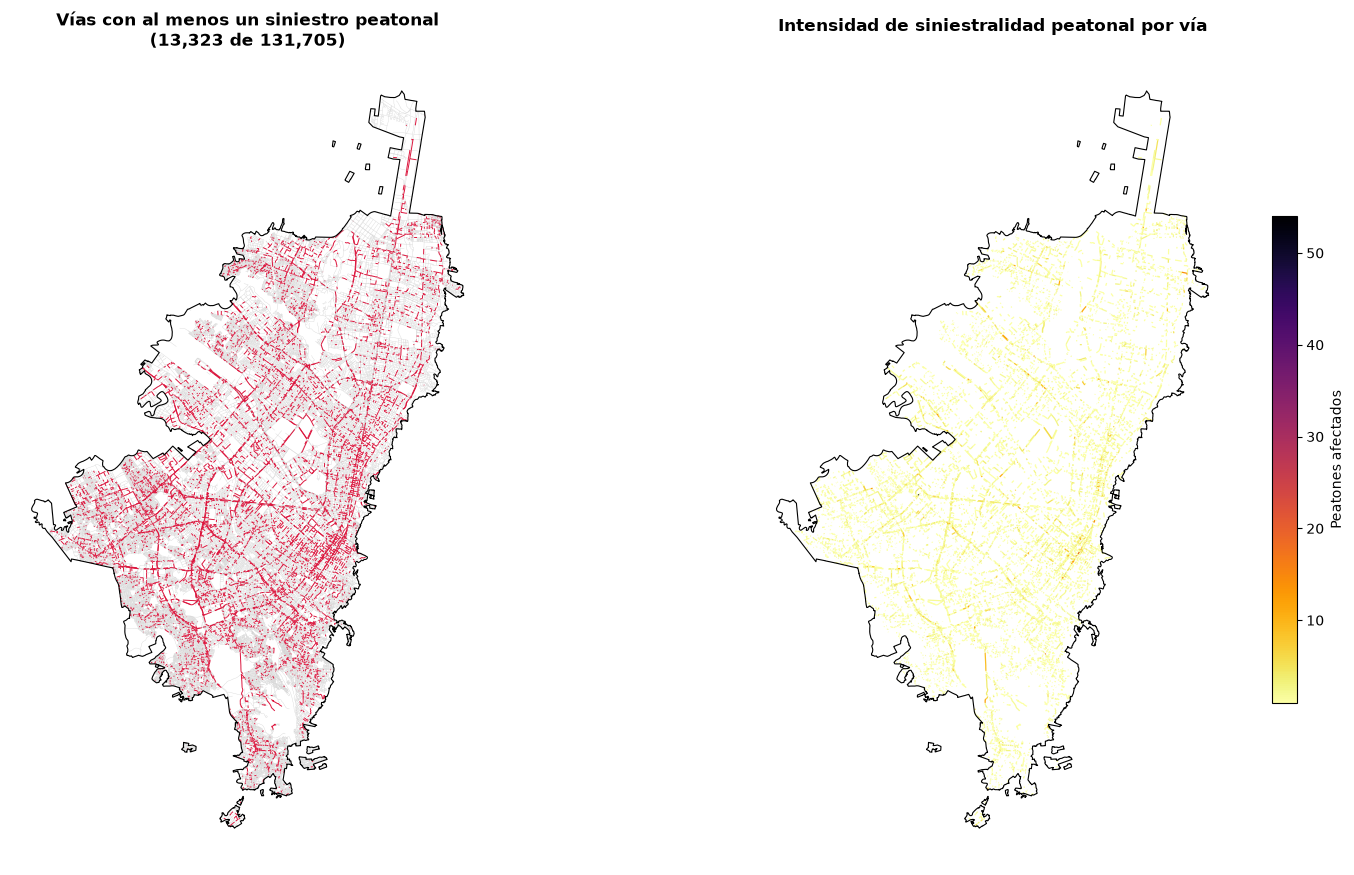

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(16, 9))

# Izquierda: red coloreada por presencia de siniestros
sin_sin = dataset_final[~dataset_final['tuvo_siniestro']]
con_sin = dataset_final[dataset_final['tuvo_siniestro']]
sin_sin.plot(ax=axes[0], color='lightgray', linewidth=0.25, zorder=1)
con_sin.plot(ax=axes[0], color='crimson', linewidth=0.7, zorder=2)
perimetro.boundary.plot(ax=axes[0], color='black', linewidth=0.8, zorder=3)
axes[0].set_title(f'Vías con al menos un siniestro peatonal\n'
                  f'({len(con_sin):,} de {len(dataset_final):,})', fontweight='bold')

# Derecha: intensidad
con_sin.plot(ax=axes[1], column='n_peatones_afectados', cmap='inferno_r',
             linewidth=0.9, legend=True, scheme=None,
             legend_kwds={'label': 'Peatones afectados', 'shrink': 0.6})
perimetro.boundary.plot(ax=axes[1], color='black', linewidth=0.8, zorder=3)
axes[1].set_title('Intensidad de siniestralidad peatonal por vía', fontweight='bold')

for ax in axes:
    ax.set_axis_off()
plt.tight_layout(); plt.show()

## 7. Exportación

Se exporta el dataset a nivel de vía.

In [29]:
c = dataset_final.geometry.centroid          # ya en EPSG:3116 (metros)
dataset_final['x_m'] = c.x.to_numpy()
dataset_final['y_m'] = c.y.to_numpy()


In [30]:
salida = f'{DIR_PROC}/segmentos_unificado.gpkg'

# Capa principal de análisis
dataset_final.to_file(salida, layer='segmentos', driver='GPKG')

# Versión tabular para modelado (sin geometría)
cols_drop = ['seg_id', 'vial_id', 'geometry', 'MVITIPO', 'MVISVIA', 'localidad',
       'dist_puente_m', 'long_peatonal_cercano_m',
       'n_peatones_afectados', 'pct_nocturno', 'ano_min',
       'ano_max', 'tiene_infra_peatonal', 'tuvo_siniestro']
# 'localidad' se descarta como texto (igual que MVITIPO/MVISVIA); 'poblacion_localidad'
# sí se conserva: es la covariable numérica de exposición poblacional por vía.
dataset_final = dataset_final.fillna(0)
dataset_final.drop(columns=cols_drop).to_csv(
    f'{DIR_PROC}/segmentos_unificado.csv', index=False)

# Tabla de siniestralidad normalizada por población (anexo de proyecciones), por localidad y año
if COL_LOCALIDAD_SIN and COL_ANIO_SIN:
    resumen_localidad_anio.to_csv(f'{DIR_PROC}/siniestros_tasa_100k_localidad_anio.csv', index=False)

print('GeoPackage:', salida, '| capa: segmentos')
print('CSV       :', f'{DIR_PROC}/segmentos_unificado.csv')
if COL_LOCALIDAD_SIN and COL_ANIO_SIN:
    print('CSV       :', f'{DIR_PROC}/siniestros_tasa_100k_localidad_anio.csv')
print(f'\nDataset final: {dataset_final.shape[0]:,} vías x {dataset_final.shape[1]} columnas')

GeoPackage: Data/processed/segmentos_unificado.gpkg | capa: segmentos
CSV       : Data/processed/segmentos_unificado.csv
CSV       : Data/processed/siniestros_tasa_100k_localidad_anio.csv

Dataset final: 131,705 vías x 27 columnas


In [32]:
dataset_final.head()

,seg_id,vial_id,long_seg_m,geometry,MVITIPO,MVISVIA,MVI_VELREG,MVINUMC,dist_puente_m,dist_puente_peatonal_m,dist_puente_vehicular_m,dist_semaforo_m,dist_peatonal_m,long_peatonal_cercano_m,n_peatones_afectados,n_siniestros,pct_nocturno,n_herido,n_muerto,ano_min,ano_max,localidad,poblacion_localidad,tiene_infra_peatonal,tuvo_siniestro,x_m,y_m
0,S0000000,91428,30.958381,"LINESTRING (988757.414 997892.228, 988727.382 ...",CL,SD,30.0,2.0,2149.708556,2149.708556,2248.410504,1410.063301,0.0,0.0,0,0,0.0,0,0,0.0,0.0,CIUDAD BOLIVAR,627701.0,False,False,988742.398218,997888.469685
1,S0000001,103844,35.729601,"LINESTRING (988786.272 997913.035, 988771.253 ...",CL,SD,30.0,2.0,2130.397897,2130.397897,2218.697332,1378.963885,0.0,0.0,0,0,0.0,0,0,0.0,0.0,CIUDAD BOLIVAR,627701.0,False,False,988772.316261,997901.961403
2,S0000002,136273,31.900881,"LINESTRING (988935.627 997898.403, 988910.141 ...",DG,SD,30.0,1.0,2108.777826,2108.777826,2173.881717,1232.553221,0.0,0.0,0,0,0.0,0,0,0.0,0.0,CIUDAD BOLIVAR,627701.0,False,False,988922.883791,997907.996305
3,S0000003,122955,48.556662,"LINESTRING (988745.967 997939.416, 988752.964 ...",KR,SD,30.0,1.0,2102.083822,2102.083822,2208.676848,1410.063301,0.0,0.0,0,0,0.0,0,0,0.0,0.0,CIUDAD BOLIVAR,627701.0,False,False,988751.718378,997915.828546
4,S0000004,106448,21.075999,"LINESTRING (988910.141 997917.589, 988899.533 ...",DG,SD,30.0,1.0,2106.174016,2106.174016,2164.688445,1255.390362,0.0,0.0,0,0,0.0,0,0,0.0,0.0,CIUDAD BOLIVAR,627701.0,False,False,988902.070753,997924.257965


## 8. Resumen metodológico

**Unidad de análisis.** Cada vía original de la Malla Vial Integral (tras explotar
multipartes y descartar geometrías por debajo de `UMBRAL_RUIDO`) se conserva **completa**, con
su longitud real (`long_seg_m`), en vez de subdividirse en tramos de longitud fija. Esto evita
introducir cortes artificiales; el costo es que la longitud de las vías ahora varía mucho
entre vías cortas y avenidas largas, así que cualquier comparación de conteos crudos entre
vías debería tener en cuenta esa longitud (por ejemplo, usándola como *offset* de exposición
en un modelo de conteos).

**Agregación por vecino más próximo.** 
Cada elemento de las capas de infraestructura y de siniestralidad se asigna a la vía más
cercana mediante `sjoin_nearest`. Puentes y semáforos se resumen como **distancia al más
cercano** (`dist_puente_m`, `dist_semaforo_m`), sin límite de distancia. Malla peatonal y
siniestros se **agregan** (longitud sumada / conteo) a la vía más cercana dentro de un umbral
de distancia (`UMBRAL_PEATONAL_M`, `UMBRAL_SINIESTROS_M`), para no asignarle a una vía
infraestructura o siniestros que en realidad están lejos de ella. Al ser vecino más próximo
(no una zona que puede solaparse), cada elemento pertenece a una única vía.

**Variable objetivo.** El conteo de siniestros por vía (`n_peatones_afectados`,
`n_siniestros`). Se retiraron del dataset la edad media de las víctimas
(`edad_media_victima`), el conteo de ilesos (`n_ileso`) y la tasa por 100 m
(`siniestros_por_100m`): las dos primeras no aportaban a la definición del objetivo, y la
tercera dejó de tener sentido al no haber ya una comparación entre distintos tamaños de
segmento.

**Integración con proyecciones de población.** La población se incorpora de dos formas
independientes, cada una con su propia unidad de análisis:
- **A cada vía** (`poblacion_localidad`, sección 4.7.1-4.7.3): por posición espacial del
  centroide de la vía dentro de una localidad, con la población representativa de esa
  localidad promediada entre 2018 y 2020 (el tramo del anexo DANE/SDP 2018-2035 que se
  solapa con el periodo de estudio 2015-2020). No depende de que la vía tenga siniestros
  asignados, así que cubre el 100% de la red, a diferencia del enfoque anterior que solo
  llegaba a las vías con un siniestro cercano.
- **A cada siniestro** (sección 4.7.4): la población de su localidad en el año exacto en
  que ocurrió, usada únicamente para la tasa descriptiva de siniestros por 100.000
  habitantes por localidad-año (`siniestros_tasa_100k_localidad_anio.csv`). Esta tabla no
  alimenta el dataset por vía.

**Puntos a revisar con las salidas reales:**
- El % de cobertura de la sección 4.6 dice si `UMBRAL_SINIESTROS_M` (30 m) es razonable o hay
  que ajustarlo.
- El desbalance de la sección 5.1 condiciona la elección de modelo y métricas — con vías de
  longitud muy variable, probablemente convenga modelar tasas o usar `long_seg_m` como offset
  en vez del conteo crudo directamente.
- La sección 4.7 requiere la capa de localidades en `Data/raw/` (no incluida todavía) y queda
  pendiente confirmar el nombre real de su columna de localidad y si el promedio 2018-2020 es
  el criterio deseado para representar la población del periodo 2015-2020.